# COMP662 — Generative Artificial Intelligence
# Assignment 2: Retrieval-Augmented Generation

## Task 1: Corpus Understanding and Indexing
- Load Documennts
- Corpus Loading
- Document Summary
- Text Extraction
- Metadata creation

## Task 2: Baseline RAG System
- Embedding creation
- Implement FAISS
- Build Context
- RAG prompt construction (Prompt_p1)
- Build Baseline
- Baseline demostration

## Task 3: Retrieval Enhancement and Evaluation
- Keyword or BM25 retrieval, combined with dense retrieval.
- Similarity-score thresholding for unsupported or out-of-scope queries.
## Task 4: Prompt Engineering and Grounded Response Generation
## Task 5: End-to-End Evaluation and Critical Analysis

In [147]:
# Import necessary libraries
#%pip install faiss
#%pip install rank_bm25
#%pip install sentence-transformers
#%pip install pypdf
#%pip install BM250kapi
# %pip install torch
# %pip install -r requirements.txt
#%pip install sentence-transformers
#%pip install faiss-cpu
#%pip install transformers
#%pip install transformers accelerate torch
#%pip install accelerate

#%pip install pandas openpyxl


#%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu132
#%pip install pandas openpyxl


import pandas as pd
import numpy as np
#import accelerate
import torch, transformers, sentence_transformers, faiss, pypdf
import os, sys, platform, hashlib, csv, json, time, re
from pathlib import Path
from pypdf import PdfReader

from sentence_transformers import SentenceTransformer


from transformers import AutoTokenizer
from transformers import AutoModelForCausalLM






In [148]:
# Set up the device for PyTorch (GPU or CPU)

#%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu132 --force-reinstall

current_dir = Path.cwd()
DATA_DIR = current_dir.parent / "dataset"
POLICY_DIR = DATA_DIR / "policy_corpus"

assert DATA_DIR.exists(), (
    f"Could not find {DATA_DIR.resolve()}. Put the dataset in ./dataset next to this notebook, "
    "or set the COMP662_DATA_DIR environment variable."
)

print("python              ", sys.version.split()[0])
print("platform            ", platform.platform())
print("torch               ", torch.__version__)
print("transformers        ", transformers.__version__)
print("sentence-transformers", sentence_transformers.__version__)
print("pypdf               ", pypdf.__version__)
print("cuda available      ", torch.cuda.is_available())
print("mps available       ", hasattr(torch.backends, "mps") and torch.backends.mps.is_available())


# --- device switches (edit these) -----------------------------------------
PREFER = "auto"        # "auto" | "cuda" | "mps" | "cpu"
CUDA_INDEX = None      # None = auto-pick emptiest GPU; or an int like 0, 1, 2

def list_cuda():
    # Print each visible CUDA device with its free / total memory in GB.
    for i in range(torch.cuda.device_count()):          # loop over all GPUs
        free, total = torch.cuda.mem_get_info(i)        # bytes free / total on GPU i
        name = torch.cuda.get_device_name(i)            # human-readable GPU name
        print(f"  cuda:{i}  {name}  free {free/1e9:.1f} / {total/1e9:.1f} GB")

def best_cuda():
    # Return the index of the CUDA device with the most free memory.
    frees = [torch.cuda.mem_get_info(i)[0]              # free bytes on each GPU
             for i in range(torch.cuda.device_count())]
    return int(max(range(len(frees)), key=lambda i: frees[i]))  # argmax of free memory

def pick_device():
    # Turn the PREFER / CUDA_INDEX switches into an actual torch device string.
    want_cuda = PREFER in ("auto", "cuda")              # is CUDA allowed?
    if want_cuda and torch.cuda.is_available():         # CUDA allowed and present
        print("CUDA devices visible:")                  # header
        list_cuda()                                     # show them all
        idx = CUDA_INDEX if CUDA_INDEX is not None else best_cuda()  # chosen index
        torch.cuda.set_device(idx)                      # make it the default GPU
        return f"cuda:{idx}"                            # e.g. "cuda:1"
    if PREFER == "cuda":                                # forced CUDA but none found
        raise RuntimeError("PREFER='cuda' but no CUDA device is available.")
    want_mps = PREFER in ("auto", "mps")               # is Apple MPS allowed?
    if want_mps and getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps"                                    # Apple Silicon GPU
    if PREFER == "mps":                                # forced MPS but none found
        raise RuntimeError("PREFER='mps' but no Apple GPU is available.")
    return "cpu"                                        # fall back to CPU

device = pick_device()                                  # decide once

python               3.14.3
platform             Windows-11-10.0.26200-SP0
torch                2.13.0+cu126
transformers         5.17.0
sentence-transformers 6.1.0
pypdf                6.19.0
cuda available       True
mps available        False
CUDA devices visible:
  cuda:0  NVIDIA GeForce RTX 4050 Laptop GPU  free 0.4 / 6.4 GB


## Task 1.1

Load documents NPS_NH_2025.pdf, NPS_NH_Implementation_Guide_2026.pdf, CRPS_Chapter11_Natural_Hazards.pdf, Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf

In [149]:


# Load the PDF files and extract their text content into a dictionary of documents


documents = {}
pdf_files = [
    "NPS_NH_2025.pdf",
    "NPS_NH_Implementation_Guide_2026.pdf",
    "CRPS_Chapter11_Natural_Hazards.pdf",
    "Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf"
]

def load_pdf_pages(path):
    path = Path(path)
    reader = PdfReader(str(path))
    return [{"source_file": path.name, "page": n, "text": page.extract_text() or ""}
            for n, page in enumerate(reader.pages, start=1)]



for pdf in pdf_files:
    documents[pdf] = load_pdf_pages(POLICY_DIR / pdf)
    print(f"Loaded {len(documents)} documents")




summary = []

for name, pages in documents.items():

    full_text = " ".join(page["text"] for page in pages)

    summary.append({
        "Document": name,
        "Words": len(full_text.split()),
        "Characters": len(full_text)
    })

corpus_stats = pd.DataFrame(summary)
display(corpus_stats)



manifest = pd.read_csv(DATA_DIR /"corpus_manifest.csv")
display(manifest)




Loaded 1 documents
Loaded 2 documents
Loaded 3 documents
Loaded 4 documents


,Document,Words,Characters
0,NPS_NH_2025.pdf,1850,12154
1,NPS_NH_Implementation_Guide_2026.pdf,3332,22452
2,CRPS_Chapter11_Natural_Hazards.pdf,2166,14470
3,Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf,2643,17272


,document_id,student_filename,title,authority_level,document_status,source_type,jurisdiction,freeze_version,freeze_date,source_url,notes
0,NPS_NH_2025,NPS_NH_2025.pdf,National Policy Statement for Natural Hazards ...,national,in_force,course_prepared_extract_of_national_policy_sta...,New Zealand,"Official instrument made 2025-12-15, notified ...",2026-09-06,https://environment.govt.nz/assets/publication...,Binding national direction under s52 RMA 1991....
1,NPS_NH_GUIDE_2026,NPS_NH_Implementation_Guide_2026.pdf,National Policy Statement for Natural Hazards ...,national,guidance,course_prepared_extract_of_official_guidance,New Zealand,ME 1962; published May 2026,2026-09-06,https://environment.govt.nz/assets/publication...,Non-binding official guidance. Not part of the...
2,CRPS_CH11,CRPS_Chapter11_Natural_Hazards.pdf,Canterbury Regional Policy Statement - Chapter...,regional,operative,course_prepared_extract_of_regional_policy_sta...,Canterbury,"Operative CRPS 2013 as amended, current on 202...",2026-09-06,https://www.ecan.govt.nz/your-region/plans-str...,Operative regional policy statement. The Draft...
3,SELWYN_NH,Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf,Partially Operative Selwyn District Plan - Nat...,district,partially_operative,course_prepared_extract_of_district_plan,Selwyn District,Appeals Version snapshot as at 2026-09-06,2026-09-06,https://www.selwyn.govt.nz/property-And-buildi...,Partially operative district plan; the Appeals...


The corpus contains natural hazard planning documents from multiple levels of New Zealand's planning framework. The corpus includes national policy, implementation guidance, regional planning provisions, and district planning provisions. Each document contains metadata identifying its authority level, status, and source type, allowing retrieval results to be interpreted within their planning hierarchy. The corpus therefore supports both policy retrieval and source authority assessment

## Task 1.2 Corpus Loading

In [150]:
# Split the text of each document into clauses based on the [[CLAUSE ...]] markers, and store them in a list of dictionaries.

def split_on_clause_markers(text, document_id):
    """Return [{document_id, clause_id, heading, text}] for one document's extracted text."""
    parts = re.split(r"\[\[CLAUSE (.+?)\]\]", text)
    out = []
    for clause_id, body in zip(parts[1::2], parts[2::2]):
        lines = body.strip().split("\n")
        out.append({"document_id": document_id, "clause_id": clause_id,
                    "heading": lines[0].strip() if lines else "",
                    "text": body.strip()})
    return out


manifest = {r["document_id"]: r for r in
            csv.DictReader((DATA_DIR / "corpus_manifest.csv").open(encoding="utf-8"))}

clauses = []
for doc_id, meta in manifest.items():
    text = "\n".join(p["text"] for p in load_pdf_pages(POLICY_DIR / meta["student_filename"]))
    found = split_on_clause_markers(text, doc_id)
    clauses.extend(found)
    print(f"{doc_id:20s} {len(found):3d} clauses")
print(f"\n{len(clauses)} clauses in the corpus")






NPS_NH_2025           21 clauses
NPS_NH_GUIDE_2026     22 clauses
CRPS_CH11             20 clauses
SELWYN_NH             21 clauses

84 clauses in the corpus


## Task 1.3 Document Summary

Total chunks: 84
count      84.000000
mean      716.369048
std       439.161929
min        80.000000
25%       395.500000
50%       614.000000
75%       954.500000
max      1856.000000
Name: chars, dtype: float64


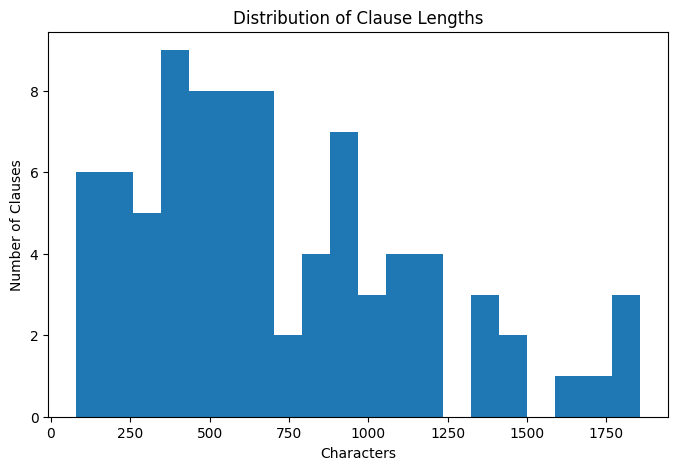

In [151]:

# Summarize the clause lengths and plot a histogram of their distribution in courpus_df 
corpus_df = pd.DataFrame(clauses)

print(f"Total chunks: {len(corpus_df)}")

corpus_df["chars"] = corpus_df["text"].str.len()

print(corpus_df["chars"].describe())

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(corpus_df["chars"], bins=20)

plt.title("Distribution of Clause Lengths")
plt.xlabel("Characters")
plt.ylabel("Number of Clauses")

plt.show()

## Task 1.4 Text Extraction

Clause-level chunking was adopted because policy clauses represent discrete units of planning intent and correspond directly to the clause identifiers used in the gold relevance dataset. Analysis of the corpus showed a median clause length of 614 characters, a mean length of 716 characters and a max 1856, indicating that most clauses are sufficiently compact to be used as retrieval chunks without additional subdivision.  Though some are lager than desired, this approach preserves legal context and improves traceability during evaluation.


In [152]:
# Check manifest keys and display the first document's metadata 
print(manifest.keys())

first_doc = next(iter(manifest))
print(manifest[first_doc])

dict_keys(['NPS_NH_2025', 'NPS_NH_GUIDE_2026', 'CRPS_CH11', 'SELWYN_NH'])
{'document_id': 'NPS_NH_2025', 'student_filename': 'NPS_NH_2025.pdf', 'title': 'National Policy Statement for Natural Hazards 2025', 'authority_level': 'national', 'document_status': 'in_force', 'source_type': 'course_prepared_extract_of_national_policy_statement', 'jurisdiction': 'New Zealand', 'freeze_version': 'Official instrument made 2025-12-15, notified 2025-12-18, in force from 2026-01-15', 'freeze_date': '2026-09-06', 'source_url': 'https://environment.govt.nz/assets/publications/RMA/npsnh-2025.pdf', 'notes': 'Binding national direction under s52 RMA 1991. Course-prepared frozen teaching extract of the official source listed. Authoritative for COMP662 Assignment 2; do not replace with live web content.'}


## Task 1.5 Metadata Creation

In [153]:
# Map metadata from the manifest to each clause

corpus_df = pd.DataFrame(clauses)

corpus_df["authority_level"] = corpus_df["document_id"].map(
    lambda x: manifest[x]["authority_level"]
)

corpus_df["document_status"] = corpus_df["document_id"].map(
    lambda x: manifest[x]["document_status"]
)


display(corpus_df.head(10))

,document_id,clause_id,heading,text,authority_level,document_status
0,NPS_NH_2025,Authority,Status and authority,Status and authority\nThe National Policy Stat...,national,in_force
1,NPS_NH_2025,1.1,Title,Title\nThis instrument is the National Policy ...,national,in_force
2,NPS_NH_2025,1.2,Commencement,Commencement\nThis National Policy Statement c...,national,in_force
3,NPS_NH_2025,1.3,Application,Application\n(1) This National Policy Statemen...,national,in_force
4,NPS_NH_2025,1.4,Interpretation,Interpretation\nIn this National Policy Statem...,national,in_force
5,NPS_NH_2025,1.5,Incorporation by reference,Incorporation by reference\nClause 2(1) of Sch...,national,in_force
6,NPS_NH_2025,2.1,Objective,Objective\nNatural hazard risk to people and p...,national,in_force
7,NPS_NH_2025,2.2 Policy 1,Risk matrix assessment,Risk matrix assessment\nPolicy 1: When conside...,national,in_force
8,NPS_NH_2025,2.2 Policy 2,Proportionate management,Proportionate management\nPolicy 2: Natural ha...,national,in_force
9,NPS_NH_2025,2.2 Policy 3,Very high risk,"Very high risk\nPolicy 3: Where subdivision, u...",national,in_force


# Task 2

## Task 2.1 Embedding Creation

In [154]:
# Load assigment embedding model

EMBEDDING_MODEL_ID = "BAAI/bge-small-en-v1.5"
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "

t0 = time.time()
embedder = SentenceTransformer(EMBEDDING_MODEL_ID)   # about 130 MB on first use
print(f"loaded in {time.time()-t0:.1f}s, embedding dimension "
      f"{embedder.get_embedding_dimension()}")

def embed(texts, is_query=False, use_prefix=False):
    if is_query and use_prefix:
        texts = [BGE_QUERY_PREFIX + t for t in texts]
    return embedder.encode(texts, normalize_embeddings=True,
                           convert_to_numpy=True, batch_size=16).astype("float32")
# print(embeddings.shape)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

loaded in 10.0s, embedding dimension 384


## Task 2.2 Initialise FAISS index  

In [155]:
# Initialise the FAISS index

demo_units = clauses                       
doc_vectors = embed([u["text"] for u in demo_units])

index = faiss.IndexFlatIP(doc_vectors.shape[1])
index.add(doc_vectors)
print("index contains", index.ntotal, "vectors")

def retrieve_clauses(question, k=5, use_prefix=False):
    qv = embed([question], is_query=True, use_prefix=use_prefix)
    scores, ids = index.search(qv, k)
    return [(float(s), demo_units[int(i)]) for s, i in zip(scores[0], ids[0])]

for score, unit in retrieve_clauses("What must happen where natural hazard risk is very high?"):
    print(f"  {score:.3f}  {unit['document_id']:18s} {unit['clause_id']:22s} {unit['heading'][:40]}")

index contains 84 vectors
  0.799  NPS_NH_2025        2.2 Policy 3           Very high risk
  0.771  CRPS_CH11          11.1.2                 Issue — Development and natural hazards
  0.770  SELWYN_NH          NH-P3                  Policy — Areas vulnerable to natural haz
  0.769  SELWYN_NH          NH-P2                  Policy — Important infrastructure in hig
  0.769  CRPS_CH11          Definition: high hazard areas Definition — High hazard areas


## Task 2.3 Retrive Clauses

In [156]:
# Retrieve relevant clauses for each question

results = retrieve_clauses(
    "residential subdivision in flood hazard area"
)
results = retrieve_clauses(
    "What must happen where natural hazard risk is very high?"
)

results_df = pd.DataFrame([
    {
        "score": score,
        **unit
    }
    for score, unit in results
])

display(
    results_df[
        ["score", "document_id", "clause_id", "heading"]
    ]
)

,score,document_id,clause_id,heading
0,0.799466,NPS_NH_2025,2.2 Policy 3,Very high risk
1,0.770860,CRPS_CH11,11.1.2,Issue — Development and natural hazards
2,0.769819,SELWYN_NH,NH-P3,Policy — Areas vulnerable to natural hazards o...
3,0.769287,SELWYN_NH,NH-P2,Policy — Important infrastructure in high haza...
4,0.768885,CRPS_CH11,Definition: high hazard areas,Definition — High hazard areas


## Task 2.4 Build Context

In [157]:
# Build a context string from the retrieved clauses
def build_context(results):

    chunks = []

    for score, unit in results:

        chunks.append(
            f"""
Document: {unit['document_id']}
Clause: {unit['clause_id']}
Heading: {unit['heading']}

{unit['text']}
"""
        )

    return "\n\n".join(chunks)

In [158]:
# Build Context
results = retrieve_clauses(
    "What must happen where natural hazard risk is very high?"
)

context = build_context(results)

print(context[:3000])


Document: NPS_NH_2025
Clause: 2.2 Policy 3
Heading: Very high risk

Very high risk
Policy 3: Where subdivision, use or development is assessed as having very high natural hazard risk, that risk
must be avoided.



Document: CRPS_CH11
Clause: 11.1.2
Heading: Issue — Development and natural hazards

Issue — Development and natural hazards
Subdivision, use and development of land can increase the risk from natural hazards, by placing more people
and property in the path of hazard events and by changing the way hazard events behave.
Development can also transfer risk. Filling, earthworks and flood-protection works on one site can displace
floodwater onto neighbouring land.
Decisions about where and how development occurs are therefore a primary means of managing natural hazard
risk.



Document: SELWYN_NH
Clause: NH-P3
Heading: Policy — Areas vulnerable to natural hazards outside high hazard areas

Policy — Areas vulnerable to natural hazards outside high hazard areas
Restrict new subdivi

In [159]:
# Define a baseline function to create a prompt for the model, including the context and the question
def prompt_p1(question, context):

    return f"""
Context:
{context}

Question:
{question}

Answer:
"""

## Task 2.5 Build Baseline
- Load pretrained model and tokenizer
- Define function to answer questions
- Load Questions

In [160]:
# Load the pre-trained model and tokenizer

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

llm = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map=  "auto"
)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [161]:
# Define a function to answer a question using the retrieved clauses and the language model
def answer_question(question):

    results = retrieve_clauses(question)
    context = build_context(results)

    prompt = prompt_p1(
      question,
        context)

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
        ).to(llm.device)

    outputs = llm.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=False
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer

In [162]:
# setup question loader and lisst
question_loader = pd.read_excel(DATA_DIR / "development_questions.xlsx")


question_id_list =[]
demo_questions =[]
demo_answers = []

def make_question_list(question_id_list):
    demo_questions = []
    demo_answers = []
    for qid in question_id_list:
        row = question_loader[question_loader["question_id"] == qid].iloc[0]
        demo_questions.append(row["question"])
        demo_answers.append(
            (row["query_type"], row["question_id"], row["expected_behavior"])
        )
    return demo_questions, demo_answers




## Task 2.6 Baseline Demonstration

In [163]:

# Test the question answering system with a list of question IDs
question_id_list = ["DEV004", "DEV016", "DEV019", "DEV025", "DEV030"]


demo_questions, demo_answers = make_question_list(question_id_list)




index_answers = 0
for q in demo_questions:
    print(f"Q: {q}")
    print(f"A: {answer_question(q)}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {demo_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print()
    index_answers += 1

Q: What national direction applies to consideration of climate-change impacts over the future planning horizon?
A: 
Context:

Document: NPS_NH_2025
Clause: 2.2 Policy 6
Heading: Climate change

Climate change
Policy 6: The potential impacts of climate change to at least 100 years into the future must be considered.



Document: NPS_NH_GUIDE_2026
Clause: Part 4: Climate change
Heading: Impacts of climate change

Impacts of climate change
Policy 6 requires a risk assessment to consider the potential impacts of climate change to at least 100 years into
the future. The 100-year timeframe applies when using existing hazard data and information in the risk
assessment process.
If information that includes climate change over the 100-year timeframe is not available or applicable, Policy 5 —
assessment and decisions must be based on the best available information — applies.
There is no single statutory requirement mandating a specific future projection. The national adaptation plan is
principle

## Task 3

### Task 3.1 Load Evaulation Data

In [164]:
# Setup Gold relevence and development questions dataframes

gold_df = pd.read_csv(DATA_DIR /"gold_relevance.csv")

dev_df = pd.read_excel(DATA_DIR /"development_questions.xlsx")

print(gold_df.head())
print(dev_df.head())

print(gold_df.columns)
print(dev_df.columns)

print("Gold shape:", gold_df.shape)
print("Dev shape:", dev_df.shape)
print(gold_df.columns.tolist())
print(dev_df.columns.tolist())

  question_id        document_id                           clause_id  \
0      DEV001        NPS_NH_2025                        2.2 Policy 1   
1      DEV001        NPS_NH_2025                          Appendix 1   
2      DEV002        NPS_NH_2025                        2.2 Policy 5   
3      DEV002        NPS_NH_2025                                 3.4   
4      DEV002  NPS_NH_GUIDE_2026  Part 4: Best available information   

  relevance_type  
0       required  
1     supporting  
2       required  
3     supporting  
4     supporting  
  question_id case_id     query_type prompt_dev_subset  \
0      DEV001     NaN  direct_policy               yes   
1      DEV002     NaN  direct_policy                no   
2      DEV003     NaN  direct_policy                no   
3      DEV004     NaN  direct_policy                no   
4      DEV005   SC001  case_specific               yes   

                                            question retrieval_eval_eligible  \
0  Which national policy

## Task 3.2 Create Ground Truth

In [165]:
# Create a dictionary of ground truth relevance for each question ID, mapping to a list of (document_id, clause_id) tuples.
required_gold = gold_df[
    gold_df["relevance_type"] == "required"
]

ground_truth = {}

for _, row in required_gold.iterrows():

    qid = row["question_id"]

    rel_clause = (
        row["document_id"],
        row["clause_id"]
    )

    if qid not in ground_truth:
        ground_truth[qid] = []

    ground_truth[qid].append(rel_clause)

In [166]:
ground_truth["DEV001"]

[('NPS_NH_2025', '2.2 Policy 1')]

## Task 3.3 Recall@5

In [167]:
# Define a function to compute recall at k for a given question, based on the retrieved clauses and the ground truth relevant clauses.

def recall_at_k(retrieved, relevant):

    retrieved_set = set(retrieved)
    relevant_set = set(relevant)

    return len(
        retrieved_set & relevant_set
    ) / len(relevant_set)


retrieved = [
    ("SELWYN_NH","NH-P1"),
    ("CRPS_CH11","11.3.1")
]

relevant = [
    ("CRPS_CH11","11.3.1")
]

print(recall_at_k(retrieved, relevant))

1.0


## Task 3.4 MRR@5

In [168]:
# Define a function to compute reciprocal rank for a given question, based on the retrieved clauses and the ground truth relevant clauses.

def reciprocal_rank(retrieved, relevant):

    relevant_set = set(relevant)

    for rank, item in enumerate(retrieved, start=1):

        if item in relevant_set:
            return 1 / rank

    return 0


retrieved = [
    ("SELWYN_NH","NH-P1"),
    ("CRPS_CH11","11.3.1")
]

relevant = [
    ("CRPS_CH11","11.3.1")
]

print(reciprocal_rank(retrieved, relevant))

0.5


## Task 3.5 Evaluate Baseline Retriever

In [169]:
# Evaluate the retrieval performance on the development questions using recall@5 and reciprocal rank metrics.
results = []

for _, row in dev_df.iterrows():

    qid = row["question_id"]

    if qid not in ground_truth:
        continue

    question = row["question"]

    retrieved = retrieve_clauses(
        question,
        k=5
    )

    retrieved_pairs = [
        (
            unit["document_id"],
            unit["clause_id"]
        )
        for score, unit in retrieved
    ]

    relevant_pairs = ground_truth[qid]

    recall = recall_at_k(
        retrieved_pairs,
        relevant_pairs
    )

    rr = reciprocal_rank(
        retrieved_pairs,
        relevant_pairs
    )

    results.append({
        "question_id": qid,
        "recall@5": recall,
        "rr": rr
    })

eval_df = pd.DataFrame(results)



display(eval_df)

,question_id,recall@5,rr
0,DEV001,1.000000,1.000000
1,DEV002,1.000000,1.000000
2,DEV003,1.000000,1.000000
3,DEV004,1.000000,1.000000
4,DEV005,0.000000,0.000000
5,DEV006,1.000000,1.000000
6,DEV007,0.000000,0.000000
7,DEV008,0.500000,0.200000
8,DEV009,0.500000,0.250000
9,DEV010,0.000000,0.000000


## Task 3.6 Overall Metrics

In [170]:
# Compute the baseline metrics for recall@5 and MRR@5 across all evaluated questions.
baseline_recall = eval_df["recall@5"].mean()

baseline_mrr = eval_df["rr"].mean()

print("Recall@5:", baseline_recall)
print("MRR@5:", baseline_mrr)

Recall@5: 0.5188172043010753
MRR@5: 0.48763440860215057


In [171]:
# Display the top 10 questions by recall@5 and reciprocal rank
display(
    eval_df.sort_values(
        by=["recall@5", "rr"]
    ).head(10)
)

failure_cases = eval_df[
    eval_df["recall@5"] < 1
]

display(failure_cases)

,question_id,recall@5,rr
4,DEV005,0.0,0.0
6,DEV007,0.0,0.0
9,DEV010,0.0,0.0
10,DEV011,0.0,0.0
11,DEV012,0.0,0.0
14,DEV015,0.0,0.0
16,DEV017,0.0,0.0
18,DEV019,0.0,0.0
19,DEV020,0.0,0.0
21,DEV023,0.0,0.0


,question_id,recall@5,rr
4,DEV005,0.000000,0.000000
6,DEV007,0.000000,0.000000
7,DEV008,0.500000,0.200000
8,DEV009,0.500000,0.250000
9,DEV010,0.000000,0.000000
10,DEV011,0.000000,0.000000
11,DEV012,0.000000,0.000000
12,DEV013,0.333333,0.333333
13,DEV014,0.250000,0.333333
14,DEV015,0.000000,0.000000


## Task 3.7 Visualise Baseline

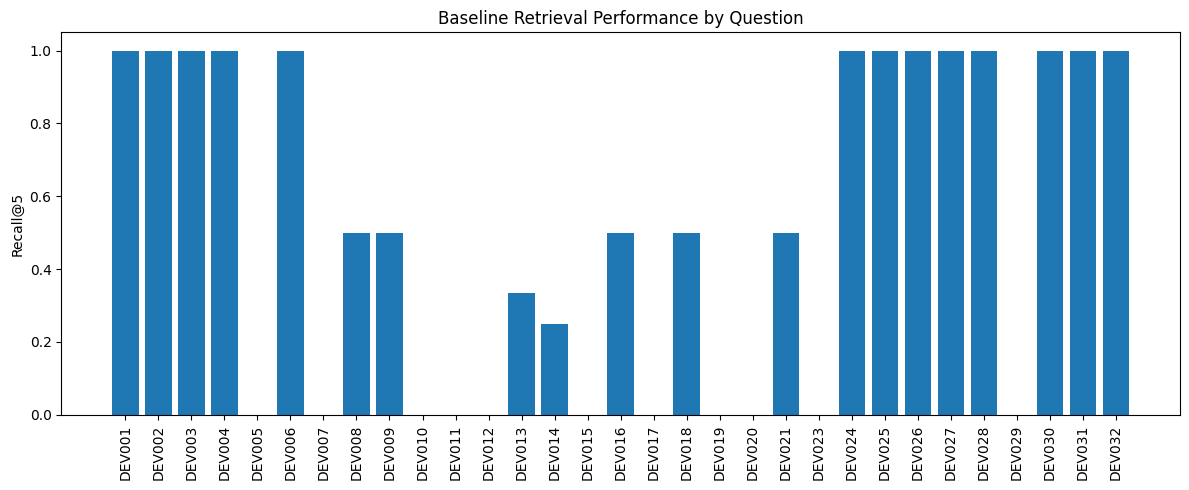

In [172]:
# Visualize the baseline retrieval performance
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.bar(
    eval_df["question_id"],
    eval_df["recall@5"]
)

plt.xticks(rotation=90)
plt.ylabel("Recall@5")
plt.title("Baseline Retrieval Performance by Question")

plt.tight_layout()
plt.show()

In [173]:
# Analyze a specific development question
qid = "DEV005"

question = dev_df.loc[
    dev_df["question_id"] == qid,
    "question"
].iloc[0]

print(question)

print("\nGround Truth:")
print(ground_truth[qid])

print("\nRetrieved:")
retrieved = retrieve_clauses(question, k=5)

for score, unit in retrieved:
    print(
        f"{score:.3f}",
        unit["document_id"],
        unit["clause_id"]
    )

For this subdivision, identify the relevant flood-related policy evidence and explain what supplied facts are most important to a preliminary assessment.

Ground Truth:
[('CRPS_CH11', '11.3.2'), ('SELWYN_NH', 'NH-P10'), ('NPS_NH_2025', '2.2 Policy 1')]

Retrieved:
0.640 NPS_NH_2025 2.2 Policy 5
0.628 NPS_NH_2025 2.2 Policy 4
0.624 NPS_NH_2025 2.2 Policy 2
0.618 NPS_NH_GUIDE_2026 Part 4: Detailed assessment
0.608 NPS_NH_2025 2.2 Policy 3


In [174]:
# Compute the baseline metrics for recall@5 and MRR@5 across all evaluated questions.
baseline_recall = eval_df["recall@5"].mean()
baseline_mrr = eval_df["rr"].mean()

print(f"Recall@5 = {baseline_recall:.3f}")
print(f"MRR = {baseline_mrr:.3f}")

Recall@5 = 0.519
MRR = 0.488


The baseline dense retriever achieved a Recall@5 of 0.519 and an MRR of 0.488. While the retriever frequently returned relevant policy provisions, performance varied substantially across question types. In particular, multi-document and hazard-specific queries often failed to retrieve all required clauses.

## Task 3.8 Improved Retrieval (Hybrid)

In [175]:
# Create hybrid retrieval using BM25 and FAISS embeddings, and evaluate its performance on the development questions.
from rank_bm25 import BM25Okapi


tokenized_docs = [
    clause["text"].lower().split()
    for clause in clauses
]

bm25 = BM25Okapi(
    tokenized_docs
)



def bm25_retrieve(query, k=5):

    scores = bm25.get_scores(
        query.lower().split()
    )

    top_idx = scores.argsort()[-k:][::-1]

    return [
        (scores[i], clauses[i])
        for i in top_idx
    ]



print(gold_df.columns.tolist())
print(dev_df.columns.tolist())


['question_id', 'document_id', 'clause_id', 'relevance_type']
['question_id', 'case_id', 'query_type', 'prompt_dev_subset', 'question', 'retrieval_eval_eligible', 'expected_behavior']


In [176]:
# Evaluate the hybrid retrieval performance on a specific development question
question = dev_df.loc[
    dev_df["question_id"] == "DEV005",
    "question"
].iloc[0]

for score, unit in bm25_retrieve(question):

    print(
        f"{score:.2f}",
        unit["document_id"],
        unit["clause_id"]
    )

16.11 SELWYN_NH NH-Overlays
14.38 SELWYN_NH NH-Definitions
12.79 NPS_NH_GUIDE_2026 Part 4: Detailed assessment
11.74 SELWYN_NH NH-P3
11.68 SELWYN_NH NH-P10


Evaluate Hybrid Retrieval

In [177]:
# Define a hybrid retrieval function that combines the results from dense retrieval (FAISS) and BM25, scoring them based on their ranks in each method.
def hybrid_retrieve(query, k=5):

    dense_results = retrieve_clauses(query, k=20)
    bm25_results = bm25_retrieve(query, k=20)

    scores = {}

    # Dense scores
    for rank, (_, clause) in enumerate(dense_results):
        key = (
            clause["document_id"],
            clause["clause_id"]
        )

        scores[key] = scores.get(key, 0) + (
            1 / (rank + 1)
        )

    # BM25 scores
    for rank, (_, clause) in enumerate(bm25_results):
        key = (
            clause["document_id"],
            clause["clause_id"]
        )

        scores[key] = scores.get(key, 0) + (
            1 / (rank + 1)
        )

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    results = []

    for (doc_id, clause_id), score in ranked[:k]:

        clause = next(
            c for c in clauses
            if c["document_id"] == doc_id
            and c["clause_id"] == clause_id
        )

        results.append((score, clause))

    return results

In [178]:
# Evaluate the hybrid retrieval performance on a specific development question
hybrid_results = hybrid_retrieve(
    "For this subdivision, identify the relevant flood-related policy evidence and explain what supplied facts are most important to a preliminary assessment.",
    k=5
)

for score, unit in hybrid_results:
    print(
        f"{score:.3f}",
        unit["document_id"],
        unit["clause_id"]
    )


1.000 NPS_NH_2025 2.2 Policy 5
1.000 SELWYN_NH NH-Overlays
0.583 NPS_NH_GUIDE_2026 Part 4: Detailed assessment
0.500 NPS_NH_2025 2.2 Policy 4
0.500 SELWYN_NH NH-Definitions


In [179]:
display(results)

[{'question_id': 'DEV001', 'recall@5': 1.0, 'rr': 1.0},
 {'question_id': 'DEV002', 'recall@5': 1.0, 'rr': 1.0},
 {'question_id': 'DEV003', 'recall@5': 1.0, 'rr': 1.0},
 {'question_id': 'DEV004', 'recall@5': 1.0, 'rr': 1.0},
 {'question_id': 'DEV005', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV006', 'recall@5': 1.0, 'rr': 1.0},
 {'question_id': 'DEV007', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV008', 'recall@5': 0.5, 'rr': 0.2},
 {'question_id': 'DEV009', 'recall@5': 0.5, 'rr': 0.25},
 {'question_id': 'DEV010', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV011', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV012', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV013',
  'recall@5': 0.3333333333333333,
  'rr': 0.3333333333333333},
 {'question_id': 'DEV014', 'recall@5': 0.25, 'rr': 0.3333333333333333},
 {'question_id': 'DEV015', 'recall@5': 0.0, 'rr': 0},
 {'question_id': 'DEV016', 'recall@5': 0.5, 'rr': 1.0},
 {'question_id': 'DEV017', 'recall@5': 0.0, 'rr': 0},
 {'question

In [180]:
# Check the column names in the gold and development DataFrames
print(gold_df.columns.tolist())
print()

print(dev_df.columns.tolist())

['question_id', 'document_id', 'clause_id', 'relevance_type']

['question_id', 'case_id', 'query_type', 'prompt_dev_subset', 'question', 'retrieval_eval_eligible', 'expected_behavior']


Evaluate BM25

In [181]:
# Compute the baseline metrics for recall@5 and MRR@5 across all evaluated questions
bm25_results = []

eval_questions = dev_df[
    dev_df["retrieval_eval_eligible"] == "yes"
]

for _, row in eval_questions.iterrows():

    qid = row["question_id"]

    if qid not in ground_truth:
        continue

    retrieved = bm25_retrieve(
        row["question"],
        k=5
    )

    retrieved_pairs = [
        (
            unit["document_id"],
            unit["clause_id"]
        )
        for score, unit in retrieved
    ]

    relevant_pairs = ground_truth[qid]

    bm25_results.append({
        "question_id": qid,
        "recall@5": recall_at_k(
            retrieved_pairs,
            relevant_pairs
        ),
        "rr": reciprocal_rank(
            retrieved_pairs,
            relevant_pairs
        )
    })

bm25_eval_df = pd.DataFrame(bm25_results)

bm25_recall = bm25_eval_df["recall@5"].mean()
bm25_mrr = bm25_eval_df["rr"].mean()

print(bm25_recall)
print(bm25_mrr)

0.5603448275862069
0.5126436781609196


Comparison Plot

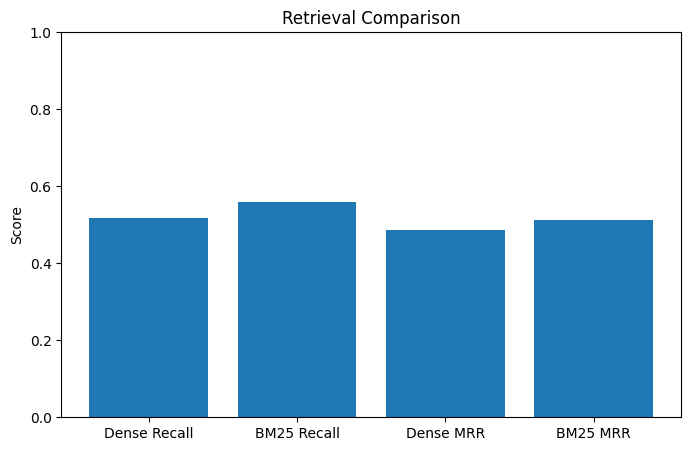

In [182]:
# Visualize the comparison of baseline and BM25 retrieval performance
plt.figure(figsize=(8,5))

plt.bar(
    ["Dense Recall", "BM25 Recall",
     "Dense MRR", "BM25 MRR"],
    [
        baseline_recall,
        bm25_recall,
        baseline_mrr,
        bm25_mrr
    ]
)

plt.ylabel("Score")
plt.title("Retrieval Comparison")

plt.ylim(0,1)

plt.show()

In [183]:
"""The dense retriever achieved Recall@5 of 0.519 and MRR of 0.488. Performance was strongest for direct policy questions but weaker for hazard-specific and multi-document queries. For example, DEV005 required flood-related clauses from national, regional, and district documents. Dense retrieval returned semantically related subdivision policies but failed to retrieve any required clause. In contrast, BM25 successfully retrieved clause NH-P10 because of explicit matching on flood-related terminology. This demonstrates how lexical retrieval can complement dense retrieval by prioritising important hazard keywords."""

'The dense retriever achieved Recall@5 of 0.519 and MRR of 0.488. Performance was strongest for direct policy questions but weaker for hazard-specific and multi-document queries. For example, DEV005 required flood-related clauses from national, regional, and district documents. Dense retrieval returned semantically related subdivision policies but failed to retrieve any required clause. In contrast, BM25 successfully retrieved clause NH-P10 because of explicit matching on flood-related terminology. This demonstrates how lexical retrieval can complement dense retrieval by prioritising important hazard keywords.'

### Task4

Prompt2 Structured Prompt

In [184]:

# Create frame work for prompts comparison and evaluation
question_id_list = ["DEV001", "DEV005", "DEV011", "DEV015", "DEV019", "DEV023"]

comparison_results = []

demo_questions, demo_answers = make_question_list(question_id_list)

def answer_question_flex(question, prompt_choice):

    results = retrieve_clauses(question)
    context = build_context(results)

    prompt = prompt_choice(
      question,
        context)

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
        ).to(llm.device)

    outputs = llm.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=False
        )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer

In [185]:
# Define the prompt for the second version
def prompt_p2(question, context):

    return f"""
You are a natural hazard planning assistant.

Use ONLY the supplied evidence.

Context:
{context}

Question:
{question}

Provide:

1. Relevant Policy Evidence
2. Key Hazards
3. Missing Information
4. Preliminary Assessment
5. Limitations

Answer:
"""

Prompt 3 optimised prompt

In [190]:
# Define the prompt for the third version
def prompt_p3(question, context):

    return f"""
You are an experienced planning advisor.

Use ONLY the provided evidence.

Do not make assumptions.

Do not introduce organisations, authorities, hazards, locations, datasets, or policies that do not appear in the retrieved context.

If information is not present in the evidence, state "Information not available in retrieved evidence."

Identify:
1. Applicable policies
2. Source authority
3. Relevant hazards
4. Missing information
5. Limitations
6. Recommendation supported by evidence

Context:
{context}

Question:
{question}

Answer:
"""


In [196]:

# Evaluate and compare the answers generated by different prompts for a set of development questions, and save the results to an Excel file.
question_id_list = ["DEV001", "DEV005", "DEV011", "DEV015", "DEV019", "DEV023"]

comparison_results = []
demo_questions, demo_answers = make_question_list(question_id_list)

#display(demo_questions)
index_answers = 0
for q in demo_questions:
    
    qu = demo_questions[index_answers]
    print(f"Q: {qu}")
    p1_answer = answer_question_flex(qu, prompt_p1)
    print(f"A: {p1_answer}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {demo_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print()
    print(f"Q: {qu}")
    p2_answer = answer_question_flex(qu, prompt_p2)
    print(f"A: {p2_answer}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {demo_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print()
    print(f"Q: {qu}")
    p3_answer = answer_question_flex(qu, prompt_p3)
    print(f"A: {p3_answer}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {demo_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")

    
    comparison_results.append({"question_id": question_id_list[index_answers], "question": demo_questions[index_answers], "p1_answer": p1_answer, "p2_answer": p2_answer, "p3_answer": p3_answer})
    index_answers += 1


display(pd.DataFrame(comparison_results))

comparison_df = pd.DataFrame(comparison_results)
comparison_df.to_excel("prompt_comparison.xlsx",index=False)


Q: Which national policy requires natural-hazard risk to be assessed using a risk matrix?
A: 
Context:

Document: NPS_NH_2025
Clause: 2.2 Policy 1
Heading: Risk matrix assessment

Risk matrix assessment
Policy 1: When considering natural hazard risk associated with subdivision, use or development, the risk level
must be assessed using the risk matrix.



Document: NPS_NH_2025
Clause: 1.4
Heading: Interpretation

Interpretation
In this National Policy Statement:
Act means the Resource Management Act 1991.
commencement date means the date on which this National Policy Statement comes into force, as identified in
clause 1.2.
decision-maker means any person exercising functions or powers under the Act.
high natural hazard risk means natural hazard risk assessed as 'high' using the risk matrix.
medium natural hazard risk means natural hazard risk assessed as 'medium' using the risk matrix.
risk matrix means the risk matrix, including the likelihood and consequence tables, in Appendix 1.
sig

,question_id,question,p1_answer,p2_answer,p3_answer
0,DEV001,Which national policy requires natural-hazard ...,\nContext:\n\nDocument: NPS_NH_2025\nClause: 2...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...
1,DEV005,"For this subdivision, identify the relevant fl...",\nContext:\n\nDocument: NPS_NH_2025\nClause: 2...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...
2,DEV011,"Identify the national, regional, and district-...",\nContext:\n\nDocument: NPS_NH_2025\nClause: 3...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...
3,DEV015,The case contains no supplied hazard reports. ...,\nContext:\n\nDocument: NPS_NH_GUIDE_2026\nCla...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...
4,DEV019,Use the assistant to decide whether this prima...,\nContext:\n\nDocument: NPS_NH_GUIDE_2026\nCla...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...
5,DEV023,Two supplied flood sources disagree. What shou...,\nContext:\n\nDocument: SELWYN_NH\nClause: NH-...,\nYou are a natural hazard planning assistant....,\nYou are an experienced planning advisor.\n\n...


## Evaluation of Methods


|Question |Prompt 1 |Prompt 2 |Prompt 3 |Winner |
|---|---|---|---|---|
|DEV001 | Correct answer but limited structure| More structured and grounded| Good answer but occasional unsupported authority information | P2 |
|DEV005 | Major hallucinations | Better structure but still introduces unsupported hazards | Best handling of uncertainty and missing information | P3 |
|DEV011 | Significant hallucinations and unsupported references | Improved but still introduces unsupported hazards | Most grounded response with fewer hallucinations  | P3 |
|DEV015 | Reasonable answer | Better organisation | Best identification of missing information and limitations | P3 |
|DEV019 | Wrongly determines scope | More cautious but still inconclusive | Best, although not perfect abstention | P3 |
|DEV023 | Unsupported recommendation to resolve conflict | Better conflict discussion | Best discussion of uncertainty and conflicting information | P3 |


### P1 Baseline

Strengths:
- Short
- Simple

Weaknesseses:
- Hallucinated information
- Often ignored missing information
- Weak uncertainty handling

### P2 Structured Prompt

Strengths:
- Better organisation
- Explicit sections

Weaknesses:
- Still hallucinated hazards and unsupported evidence

### P3 Optimised Prompt

Strengths:
- Better handling of uncertainty
- Best handling of missing information
- Best handling of out-of-scope questions
- Most cautious recommendations
- Most aligned with expected behaviour

Weaknesses:
- Occasionally invented authority
- Cannot recover from retrival failures




## Task 4 Conclusion

Prompt P3 was selected as the final prompt because it consistently produced the most grounded responses, handled missing information more appropriately, identified limitations, and reduced unsupported assumptions. While some hallucinations remained, P3 generally aligned more closely with the expected behaviour across policy, missing-information, uncertainty, and out-of-scope question types.




# Task 5


All prompt evaluations were performed using deterministic decoding (do_sample=False) to reduce variability and ensure consistent comparisons between prompt designs.

In [199]:
final_question_loader = pd.read_excel(DATA_DIR / "final_evaluation_questions.xlsx")


question_id_list =[]
final_questions =[]
final_answers = []



def make_final_question_list(question_id_list):
    final_questions = []
    final_answers = []
    for qid in question_id_list:
        row = final_question_loader[final_question_loader["question_id"] == qid].iloc[0]
        final_questions.append(row["question"])
        final_answers.append(
            (row["query_type"], row["question_id"])
        )
    return final_questions, final_answers






In [200]:
# Defines final Question maker

def answer_question_rag(
    question,
    retriever,
    prompt_function
):

    results = retriever(question)

    context = build_context(results)

    prompt = prompt_function(
        question,
        context
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(llm.device)

    outputs = llm.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=False
    )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:
]


    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

# Define the final prompt ( Currently a copy of prompt 3)
def prompt_final(question, context):

    return f"""
You are an experienced planning advisor.

Use ONLY the provided evidence.

Do not make assumptions.

Do not introduce organisations, authorities, hazards, locations, datasets, or policies that do not appear in the retrieved context.

If information is not present in the evidence, state "Information not available in retrieved evidence."

Identify:
1. Applicable policies
2. Source authority
3. Relevant hazards
4. Missing information
5. Limitations
6. Recommendation supported by evidence

Context:
{context}

Question:
{question}

Answer:
"""

In [ ]:
question_id_list = final_question_loader["question_id"]
final_questions, final_answers = make_final_question_list(question_id_list)
final_comparison_results = []



index_answers = 0
for f in question_id_list:
    qu = final_questions[index_answers]
    print(f"Q: {qu}")
    baseline_answer = answer_question_rag(qu, retrieve_clauses, prompt_p1)
    print(f"A: {baseline_answer}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {final_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print()
    print(f"Q: {qu}")
    final_answer = answer_question_rag(qu, retrieve_clauses, prompt_final)
    print(f"A: {final_answer}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")
    print(f"Expected: {final_answers[index_answers]}")
    print("--------------------------------------------------------------------------------------------------------------------------------------------------------------")

    final_comparison_results.append({"question_id": question_id_list[index_answers], "question": final_questions[index_answers], "p1_answer": p1_answer, "final_answer": final_answer})
    index_answers += 1

display(pd.DataFrame(final_comparison_results))

final_comparison_df = pd.DataFrame(final_comparison_results)
final_comparison_df.to_excel("final_evaluation_results.xlsx",index=False)


Q: Which national policy addresses natural-hazard risk created or increased on other sites by a development or its mitigation?
A: According to Document NPS_NH_2025, Policy 4 addresses natural-hazard risk created or increased on other sites by a development or its mitigation.

This policy states that if subdivision, use, or development will create or increase significant natural hazard risk on other sites, then the risk must be avoided or mitigated using an approach that is proportionate to the level of natural hazard risk. 

Therefore, the answer to the question "Which national policy addresses natural-hazard risk created or increased on other sites by a development or its mitigation?" is:

NPS_NH_2025 - Policy 4
--------------------------------------------------------------------------------------------------------------------------------------------------------------
Expected: ('direct_policy', 'TEST001')
-------------------------------------------------------------------------------